In [31]:
import subprocess
from functools import reduce
import matplotlib.pyplot as plt
import numpy as np
from analysis import generate_data

single_batch_size = 5
stride = 2
batch_counts = 3
f = lambda x, y: generate_data(
    kernel_arg="%d,%d,%d" % y,
    input_arg="%d,%d,%d" % x,
    samples=5, single_batch_size=single_batch_size,
    batch_counts=batch_counts, cpu_or_gpu='gpu', cpu_threads=0,
    stride=stride, gpu_detailed_timing=False,
    gpu_local_mem=False, gpu_pinned_mem=False,
    gpu_full_duplex=False)

In [32]:
def parse_device_info(exe_path):
    # Run the executable
    completed_process = subprocess.run(
        [exe_path],
        capture_output=True,
        text=True,
        check=False
    )
    # Parse lines with a colon
    data = {}
    for line in completed_process.stdout.splitlines():
        if ':' in line:
            key, val = line.split(':', 1)
            data[key.strip()] = val.strip()
    return data


device_info = parse_device_info('../bin/device_info')
device_info['Estimated max speed'] = \
    int(float(device_info['Max clock frequency'][:-3]) * 1e6
        * float(device_info['Estimated total cores'])
        * 2
        )
device_info['byte_move_speed'] = 112.1 * 1e9  # 112.1 GB/s

In [41]:
def theoretical_info(input_x_y_c, kernel_x_y_fc):
    # app processing times with local mem off
    operation_per_pixel = 19 * kernel_x_y_fc[0] * kernel_x_y_fc[1] * input_x_y_c[2]
    memory_ops_per_pixel = 2 * kernel_x_y_fc[0] * kernel_x_y_fc[1] * input_x_y_c[2]

    # === 1. Compute output spatial dimensions (VALID padding) ===
    H_in, W_in, C_in = input_x_y_c
    K_h, K_w, C_out = kernel_x_y_fc
    H_out = (H_in - K_h) // stride + 1
    W_out = (W_in - K_w) // stride + 1
    out_size = H_out * W_out * C_out

    flops = (single_batch_size * out_size) * batch_counts * operation_per_pixel
    bytes_moved = (single_batch_size * out_size) * batch_counts * memory_ops_per_pixel

    gpu_flops_power_per_sec = device_info['Estimated max speed']
    byte_move_speed = device_info['byte_move_speed']

    temp = [
        flops / gpu_flops_power_per_sec * 1000,
        bytes_moved / byte_move_speed * 1000]

    outp = {
        "Output feature map size": out_size * 2,  # bytes
        "Total FLOPs needed": flops / 1e9,  # G-Flops
        "Ideal DRAM traffic": bytes_moved / 1e6,  # MB
        "Arithmetic intensity": flops / bytes_moved,  # FLOPs/byte
        "Time-spent compute": temp[0],  # ms
        "Time-spent memory": temp[1],  # ms
        "Time-spent overall": sum(temp),  # ms
    }
    return outp


      --> 100
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 200
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 300
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 400
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 500
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 600
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 700
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 800
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 900
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 1000
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 1100
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 1200
cpu_or_gpu='gpu'
Sample 1 of 1


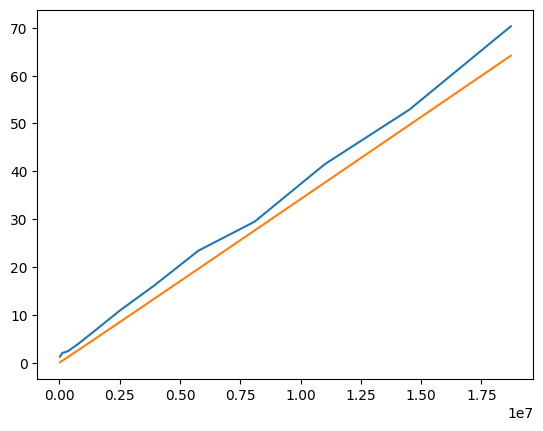

In [42]:
kernel_x_y_fc = (10, 10, 5)

compute_time_inp_size = []
input_size = []
theory_time_inp_size = []

scale = 2
for i in range(100, scale * 1300, 100):
    print("      --> %d" % i)
    input_x_y_c = (i, i, int(scale * 13 * (i / 1300) + 1))

    res = f(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    res = np.median(res)
    compute_time_inp_size.append(res)

    input_size.append(reduce(lambda x, a: x * a, input_x_y_c, 1) * single_batch_size)

    res = theoretical_info(input_x_y_c, kernel_x_y_fc)['Time-spent overall']
    theory_time_inp_size.append(res)

plt.plot(input_size, compute_time_inp_size, )
plt.plot(input_size, theory_time_inp_size, )

      --> 2
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 12
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 22
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 32
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 42
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 52
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 62
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 72
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 82
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 92
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 102
cpu_or_gpu='gpu'
Sample 1 of 1
      --> 112
cpu_or_gpu='gpu'
Sample 1 of 1


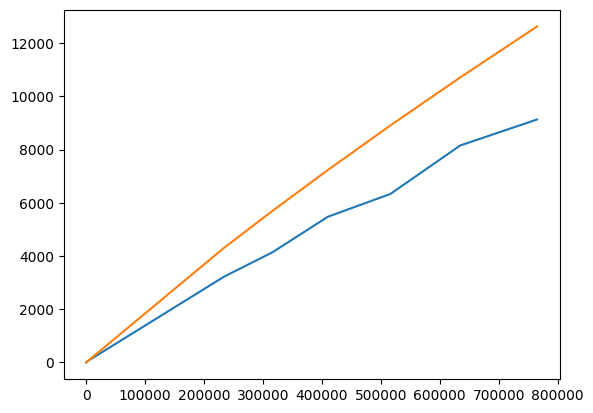

In [44]:
input_x_y_c = (1000, 1000, 3)

compute_time_kernel_size = []
kernel_size = []
theory_time_kernel_size = []
scale = 2
for i in range(2, scale * 60, 10):
    print("      --> %d" % i)
    kernel_x_y_fc = (i, i, int(scale * 30 * (i // 60) + 1))

    res = f(input_x_y_c, kernel_x_y_fc)['gpu_overall_time_0']
    res = np.median(res)
    compute_time_kernel_size.append(res)

    kernel_size.append(reduce(lambda x, a: x * a, kernel_x_y_fc, 1) * 1)

    res = theoretical_info(input_x_y_c, kernel_x_y_fc)['Time-spent overall']
    theory_time_kernel_size.append(res)

plt.plot(kernel_size, compute_time_kernel_size, )
plt.plot(kernel_size, theory_time_kernel_size, )